# Task 2 (Level 1) : Table Booking & Online Delivery Analysis

-           Loading the cleaned dataset

In [1]:
import pandas as pd

df = pd.read_csv("dataset_level1_cleaned.csv")
df.head()


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


-           Convert Yes/No to 1/0

In [3]:
df['Has_Table_Booking'] = df['Has Table booking'].map({'Yes': 1, 'No': 0})
df['Has_Online_Delivery'] = df['Has Online delivery'].map({'Yes': 1, 'No': 0})

-           Percentage of restaurants offering table booking

This calculates how many restaurants offer table booking by converting Yes/No to 1/0 and computing the mean.
Multiplying by 100 gives the percentage value.

In [4]:
table_booking_percent = df['Has_Table_Booking'].mean() * 100
table_booking_percent

np.float64(12.124384881164275)

-           Percentage offering online delivery

Same method—mean() gives the fraction, multiplied by 100 gives percentage.

In [5]:
online_delivery_percent = df['Has_Online_Delivery'].mean() * 100
online_delivery_percent

np.float64(25.662234321013504)

-           Comparing average ratings

0 = restaurants with no table booking, 
1 = restaurants with table booking

We compare their average ratings.

In [6]:
rating_comparison = df.groupby('Has_Table_Booking')['Aggregate rating'].mean()
rating_comparison

Has_Table_Booking
0    2.559359
1    3.441969
Name: Aggregate rating, dtype: float64

-           Analyze online delivery across price ranges

This shows which price range restaurants most commonly provide online delivery.

In [7]:
price_online_delivery = df.groupby('Price range')['Has_Online_Delivery'].mean() * 100
price_online_delivery


Price range
1    15.774077
2    41.310633
3    29.190341
4     9.044369
Name: Has_Online_Delivery, dtype: float64

* BAR CHARTS :

Table Booking %

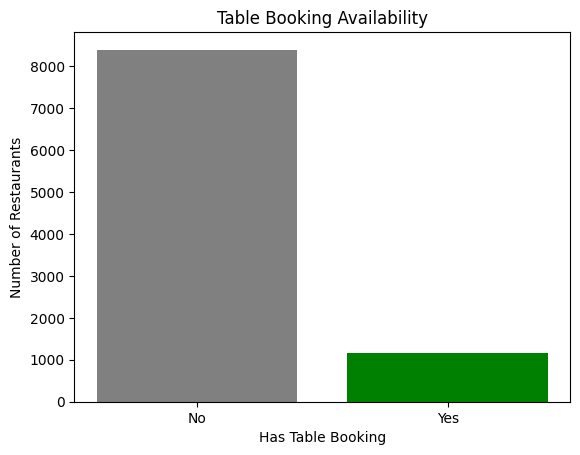

In [8]:
import matplotlib.pyplot as plt

plt.bar(['No', 'Yes'], df['Has_Table_Booking'].value_counts().sort_index(), color=['gray','green'])
plt.title("Table Booking Availability")
plt.xlabel("Has Table Booking")
plt.ylabel("Number of Restaurants")
plt.show()

Online Delivery %

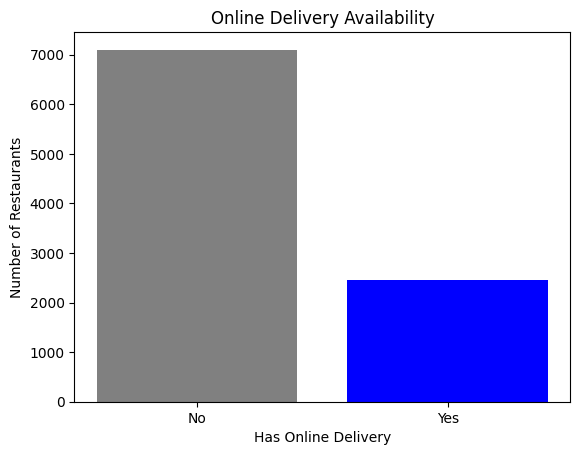

In [9]:
plt.bar(['No', 'Yes'], df['Has_Online_Delivery'].value_counts().sort_index(), color=['gray','blue'])
plt.title("Online Delivery Availability")
plt.xlabel("Has Online Delivery")
plt.ylabel("Number of Restaurants")
plt.show()


Online Delivery by Price Range

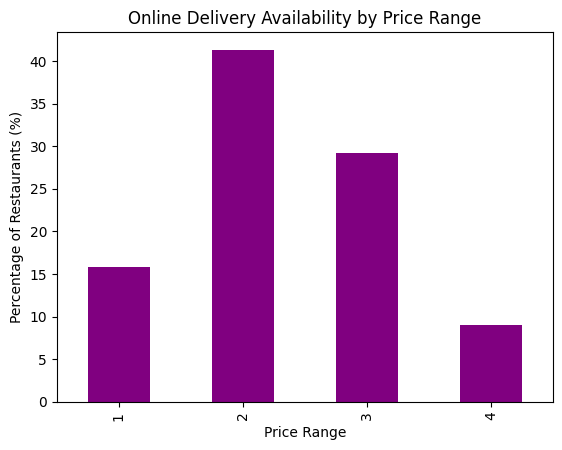

In [10]:
price_online_delivery.plot(kind='bar', color='purple')
plt.title("Online Delivery Availability by Price Range")
plt.ylabel("Percentage of Restaurants (%)")
plt.xlabel("Price Range")
plt.show()


# Observations / Insights

* Only a small percentage of restaurants offer table booking (exact % from your output).

* Online delivery is more common than table booking (insert your %).

* Restaurants that offer table booking have higher average ratings (if your numbers show this).

* Higher price range restaurants tend to offer or avoid online delivery depending on your output.